# 🏎️ Comparativa de Modelos — F1 Race Prediction

**TFM — Master en Inteligencia Artificial · UTAMED**  
**Autor:** Víctor Ferrer

---

## Objetivo

Comparar tres modelos de Machine Learning para la predicción de la posición final en carreras de F1 y justificar la elección de **XGBoost** como modelo óptimo.

| Modelo | Tipo | Justificación de inclusión |
|---|---|---|
| **Linear Regression** | Modelo lineal | Baseline de referencia. Simple, interpretable, asume relaciones lineales |
| **Random Forest** | Ensemble (bagging) | Modelo no lineal robusto. Referencia de ensemble sin boosting |
| **XGBoost** | Ensemble (boosting) | Modelo candidato final. Incluye regularización L1/L2 y early stopping |

---
# 1. ⚙️ Configuración e importaciones

In [1]:
!pip install xgboost --quiet

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.model_selection import train_test_split, cross_val_score, KFold, learning_curve
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Paleta de colores fija por modelo
COLORS = {
    "Linear Regression" : "#4C72B0",
    "Random Forest"     : "#DD8452",
    "XGBoost"           : "#55A868",
}
MODEL_NAMES = list(COLORS.keys())

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


---
# 2. 📂 Carga de datos

In [3]:
from google.colab import files

uploaded = files.upload()   # selecciona f1_dataset_v2.csv
CSV_PATH = "/content/f1_dataset_v2.csv"
print(f"Archivo cargado: {CSV_PATH}")

Saving f1_dataset_v2.csv to f1_dataset_v2.csv
Archivo cargado: /content/f1_dataset_v2.csv


In [4]:
FEATURES = [
    "grid", "driver_pos_before", "driver_wins_before",
    "constructor_pos_before", "driver_experience", "driver_age",
    "avg_finish_last3", "circuit_alt", "year", "season_progress",
]
TARGET = "positionOrder"

df = pd.read_csv(CSV_PATH)
X  = df[FEATURES]
y  = df[TARGET]

# Split 70 / 15 / 15
X_tv, X_test, y_tv, y_test = train_test_split(X, y, test_size=0.15, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_tv, y_tv, test_size=0.176, random_state=RANDOM_STATE)

print(f"Dataset  : {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(f"Train    : {len(X_train):,} muestras")
print(f"Val      : {len(X_val):,} muestras")
print(f"Test     : {len(X_test):,} muestras")

Dataset  : 25,121 filas × 11 columnas
Train    : 17,594 muestras
Val      : 3,758 muestras
Test     : 3,769 muestras


---
# 3. 🤖 Definición de modelos

- **Linear Regression** se envuelve en un `Pipeline` con `StandardScaler` porque la regresión lineal es sensible a la escala de las features.
- **Random Forest** usa 300 árboles con profundidad controlada para evitar overfitting.
- **XGBoost** usa los hiperparámetros óptimos encontrados mediante `RandomizedSearchCV` + Early Stopping en el notebook principal.

In [5]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  LinearRegression()),
    ]),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=5,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),

    "XGBoost": XGBRegressor(
        # ── Hiperparámetros optimizados ──────────────────
        n_estimators      = 863,
        learning_rate     = 0.005,
        max_depth         = 5,
        subsample         = 0.6,
        colsample_bytree  = 0.6,
        min_child_weight  = 20,
        gamma             = 2.0,
        reg_alpha         = 1.0,   # L1
        reg_lambda        = 5.0,   # L2
        # ─────────────────────────────────────────────────
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0,
    ),
}

print("Modelos definidos:")
for name in models:
    print(f"  - {name}")

Modelos definidos:
  - Linear Regression
  - Random Forest
  - XGBoost


---
# 4. 🏋️ Entrenamiento y evaluación

Para cada modelo se calculan:
- **R²**, **RMSE**, **MAE** en train y test.
- **CV R²** con validación cruzada de 5 folds sobre el conjunto de entrenamiento.
- **Gap de overfitting** = R² train − R² test.

In [6]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = {}

for name, model in models.items():
    # Entrenamiento (XGBoost usa train+val para respetar el early stopping fijado)
    model.fit(X_tv, y_tv)

    y_pred_train = model.predict(X_tv)
    y_pred_test  = model.predict(X_test)
    cv_r2        = cross_val_score(model, X_tv, y_tv, cv=kf, scoring="r2", n_jobs=-1)

    r2_train  = r2_score(y_tv, y_pred_train)
    r2_test   = r2_score(y_test, y_pred_test)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
    mae_test  = mean_absolute_error(y_test, y_pred_test)

    results[name] = {
        "y_pred_test"  : y_pred_test,
        "y_pred_train" : y_pred_train,
        "R2_train"     : r2_train,
        "R2_test"      : r2_test,
        "RMSE_test"    : rmse_test,
        "MAE_test"     : mae_test,
        "CV_R2_mean"   : cv_r2.mean(),
        "CV_R2_std"    : cv_r2.std(),
        "overfit_gap"  : r2_train - r2_test,
    }

    print(f"[{name}]")
    print(f"  R²  train/test : {r2_train:.4f} / {r2_test:.4f}")
    print(f"  RMSE test      : {rmse_test:.4f}")
    print(f"  MAE  test      : {mae_test:.4f}")
    print(f"  CV R² (5-fold) : {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")
    print(f"  Overfit gap    : {r2_train - r2_test:.4f}")
    print()

[Linear Regression]
  R²  train/test : 0.2383 / 0.2186
  RMSE test      : 6.0542
  MAE  test      : 5.0222
  CV R² (5-fold) : 0.2373 ± 0.0110
  Overfit gap    : 0.0197

[Random Forest]
  R²  train/test : 0.4963 / 0.2352
  RMSE test      : 5.9897
  MAE  test      : 4.9125
  CV R² (5-fold) : 0.2436 ± 0.0104
  Overfit gap    : 0.2612

[XGBoost]
  R²  train/test : 0.2928 / 0.2472
  RMSE test      : 5.9423
  MAE  test      : 4.9043
  CV R² (5-fold) : 0.2562 ± 0.0110
  Overfit gap    : 0.0456



---
# 5. 📊 Tabla comparativa de métricas

In [7]:
summary = pd.DataFrame({
    name: {
        "R² Train"       : round(results[name]["R2_train"], 4),
        "R² Test"        : round(results[name]["R2_test"], 4),
        "RMSE Test"      : round(results[name]["RMSE_test"], 4),
        "MAE Test"       : round(results[name]["MAE_test"], 4),
        "CV R² (media)"  : round(results[name]["CV_R2_mean"], 4),
        "CV R² (±std)"   : round(results[name]["CV_R2_std"], 4),
        "Overfit Gap"    : round(results[name]["overfit_gap"], 4),
    }
    for name in MODEL_NAMES
}).T

# Resaltar el mejor valor de cada métrica
def highlight_best(s):
    if s.name in ["R² Test", "CV R² (media)"]:
        best = s.max()
    else:
        best = s.min()
    return ["background-color: #d4edda; font-weight: bold" if v == best else "" for v in s]

display(
    summary.style
    .apply(highlight_best, axis=0)
    .set_caption("Comparativa de métricas — verde = mejor valor")
)

,R² Train,R² Test,RMSE Test,MAE Test,CV R² (media),CV R² (±std),Overfit Gap
Linear Regression,0.238300,0.218600,6.054200,5.022200,0.237300,0.011000,0.019700
Random Forest,0.496300,0.235200,5.989700,4.912500,0.243600,0.010400,0.261200
XGBoost,0.292800,0.247200,5.942300,4.904300,0.256200,0.011000,0.045600


---
# 6. 📈 Gráficas comparativas

### 6.1 Comparativa de métricas principales

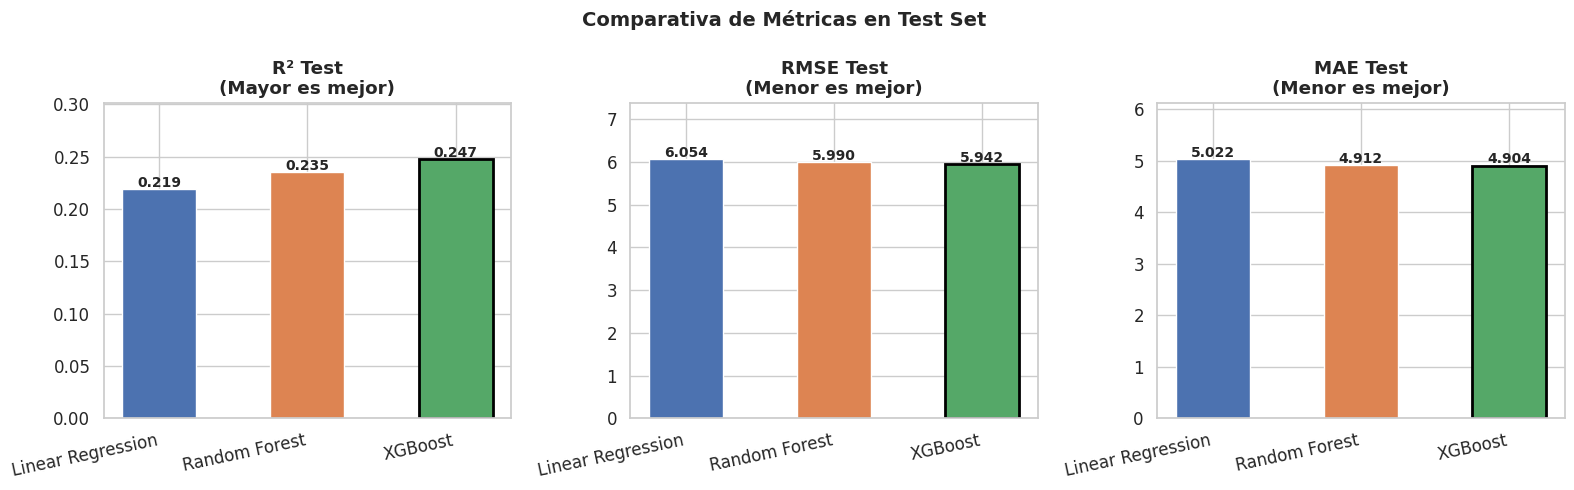

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Comparativa de Métricas en Test Set", fontsize=14, fontweight="bold")

metrics_to_plot = [
    ("R2_test",   "R² Test",   "Mayor es mejor"),
    ("RMSE_test", "RMSE Test", "Menor es mejor"),
    ("MAE_test",  "MAE Test",  "Menor es mejor"),
]

for ax, (key, label, note) in zip(axes, metrics_to_plot):
    vals   = [results[n][key] for n in MODEL_NAMES]
    colors = [COLORS[n] for n in MODEL_NAMES]
    bars   = ax.bar(MODEL_NAMES, vals, color=colors, edgecolor="white", width=0.5)

    # Marcar el mejor
    best_idx = vals.index(max(vals) if key == "R2_test" else min(vals))
    bars[best_idx].set_edgecolor("black")
    bars[best_idx].set_linewidth(2)

    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max(vals) * 0.01,
                f"{val:.3f}", ha="center", fontsize=10, fontweight="bold")

    ax.set_title(f"{label}\n({note})", fontweight="bold")
    ax.set_xticks(range(len(MODEL_NAMES)))
    ax.set_xticklabels(MODEL_NAMES, rotation=12, ha="right")
    ax.set_ylim(0, max(vals) * 1.22)

plt.tight_layout()
plt.show()

### 6.2 Análisis de overfitting — R² Train vs Test

Un modelo ideal tiene R² Train y Test cercanos entre sí. Un gap elevado indica **sobreajuste**: el modelo ha memorizado el conjunto de entrenamiento y no generaliza bien a datos nuevos.

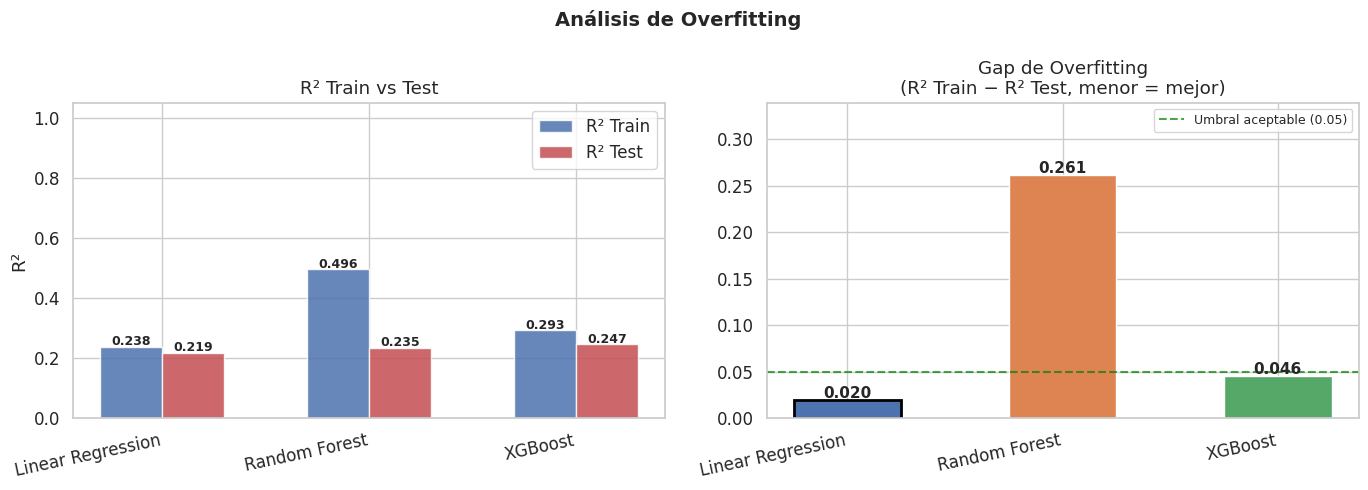

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Análisis de Overfitting", fontsize=14, fontweight="bold")

# R² Train vs Test agrupado
ax = axes[0]
x = np.arange(len(MODEL_NAMES))
w = 0.3
r2_trains = [results[n]["R2_train"] for n in MODEL_NAMES]
r2_tests  = [results[n]["R2_test"]  for n in MODEL_NAMES]

b1 = ax.bar(x - w/2, r2_trains, w, label="R² Train", color="#4C72B0", alpha=0.85)
b2 = ax.bar(x + w/2, r2_tests,  w, label="R² Test",  color="#C44E52", alpha=0.85)

for bar, val in zip(list(b1) + list(b2), r2_trains + r2_tests):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.005,
            f"{val:.3f}", ha="center", fontsize=9, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(MODEL_NAMES, rotation=12, ha="right")
ax.set_ylabel("R²")
ax.set_title("R² Train vs Test")
ax.set_ylim(0, 1.05)
ax.legend()

# Gap de overfitting
ax = axes[1]
gaps   = [results[n]["overfit_gap"] for n in MODEL_NAMES]
colors = [COLORS[n] for n in MODEL_NAMES]
bars   = ax.bar(MODEL_NAMES, gaps, color=colors, edgecolor="white", width=0.5)

best_idx = gaps.index(min(gaps))
bars[best_idx].set_edgecolor("black")
bars[best_idx].set_linewidth(2)

for bar, val in zip(bars, gaps):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(gaps) * 0.01,
            f"{val:.3f}", ha="center", fontsize=11, fontweight="bold")

ax.set_title("Gap de Overfitting\n(R² Train − R² Test, menor = mejor)")
ax.set_xticklabels(MODEL_NAMES, rotation=12, ha="right")
ax.set_ylim(0, max(gaps) * 1.3)
ax.axhline(0.05, color="green", linestyle="--", lw=1.5, alpha=0.7,
           label="Umbral aceptable (0.05)")
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

### 6.3 CV R² con barras de error — Robustez del modelo

La barra de error (±std) indica cuánto varía el rendimiento del modelo entre diferentes particiones del conjunto de entrenamiento. Barras de error pequeñas = modelo estable y generalizable.

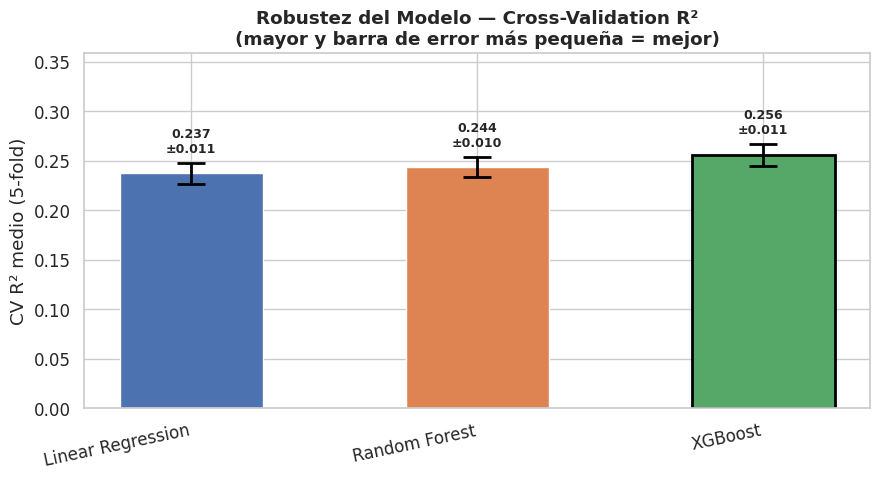

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))

cv_means = [results[n]["CV_R2_mean"] for n in MODEL_NAMES]
cv_stds  = [results[n]["CV_R2_std"]  for n in MODEL_NAMES]
colors   = [COLORS[n] for n in MODEL_NAMES]

bars = ax.bar(MODEL_NAMES, cv_means, color=colors, edgecolor="white", width=0.5,
              yerr=cv_stds, capsize=10,
              error_kw={"elinewidth": 2, "ecolor": "black", "capthick": 2})

best_idx = cv_means.index(max(cv_means))
bars[best_idx].set_edgecolor("black")
bars[best_idx].set_linewidth(2)

for bar, val, std in zip(bars, cv_means, cv_stds):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + std + 0.01,
            f"{val:.3f}\n±{std:.3f}", ha="center", fontsize=9, fontweight="bold")

ax.set_ylabel("CV R² medio (5-fold)")
ax.set_title("Robustez del Modelo — Cross-Validation R²\n(mayor y barra de error más pequeña = mejor)",
             fontweight="bold")
ax.set_xticklabels(MODEL_NAMES, rotation=12, ha="right")
ax.set_ylim(0, max(cv_means) * 1.4)

plt.tight_layout()
plt.show()

### 6.4 Curvas de aprendizaje — Comportamiento con más datos

Muestra cómo evoluciona el R² de cada modelo al aumentar el número de muestras de entrenamiento. Permite detectar si el modelo sufre de **alto sesgo** (underfitting, ambas curvas bajas y juntas) o **alta varianza** (overfitting, gran separación entre train y val).

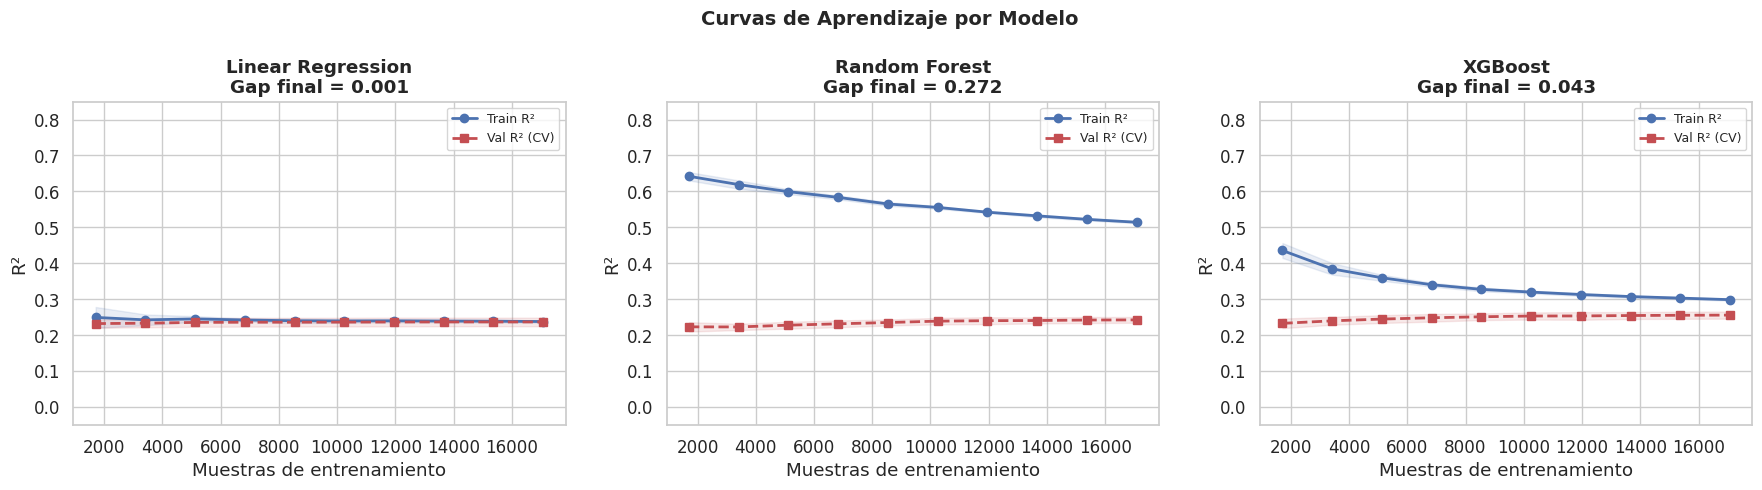

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Curvas de Aprendizaje por Modelo", fontsize=14, fontweight="bold")

for ax, name in zip(axes, MODEL_NAMES):
    model = models[name]
    train_sz, train_sc, val_sc = learning_curve(
        model, X_tv, y_tv,
        train_sizes=np.linspace(0.1, 1.0, 10),
        cv=5, scoring="r2", n_jobs=-1,
        shuffle=True, random_state=RANDOM_STATE,
    )
    tm = train_sc.mean(axis=1); ts = train_sc.std(axis=1)
    vm = val_sc.mean(axis=1);   vs = val_sc.std(axis=1)

    ax.plot(train_sz, tm, "o-", color="#4C72B0", lw=2, label="Train R²")
    ax.fill_between(train_sz, tm - ts, tm + ts, alpha=0.12, color="#4C72B0")
    ax.plot(train_sz, vm, "s--", color="#C44E52", lw=2, label="Val R² (CV)")
    ax.fill_between(train_sz, vm - vs, vm + vs, alpha=0.12, color="#C44E52")

    gap = tm[-1] - vm[-1]
    ax.set_title(f"{name}\nGap final = {gap:.3f}", fontweight="bold")
    ax.set_xlabel("Muestras de entrenamiento")
    ax.set_ylabel("R²")
    ax.set_ylim(-0.05, 0.85)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

### 6.5 Real vs Predicho — Calidad de predicción por modelo

Los puntos deberían alinearse con la diagonal punteada (predicción perfecta). La dispersión refleja el error del modelo.

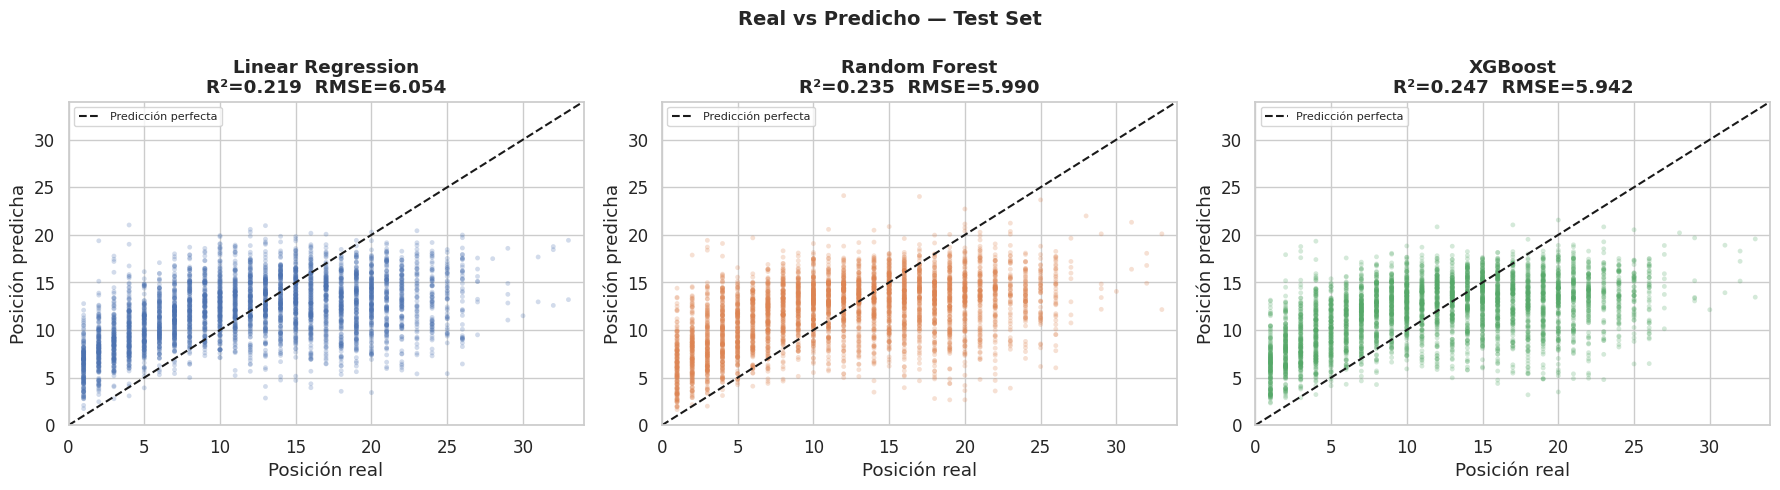

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Real vs Predicho — Test Set", fontsize=14, fontweight="bold")

y_test_arr = np.array(y_test)

for ax, name in zip(axes, MODEL_NAMES):
    y_pred = results[name]["y_pred_test"]
    ax.scatter(y_test_arr, y_pred, alpha=0.25, s=12,
               color=COLORS[name], edgecolors="none")
    lims = [0, max(y_test_arr.max(), y_pred.max()) + 1]
    ax.plot(lims, lims, "k--", lw=1.5, label="Predicción perfecta")
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel("Posición real")
    ax.set_ylabel("Posición predicha")
    ax.set_title(
        f"{name}\nR²={results[name]['R2_test']:.3f}  RMSE={results[name]['RMSE_test']:.3f}",
        fontweight="bold"
    )
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### 6.6 Distribución de residuos

Un modelo bien calibrado debería tener residuos **centrados en 0** y con una distribución aproximadamente normal. Una distribución sesgada indica errores sistemáticos.

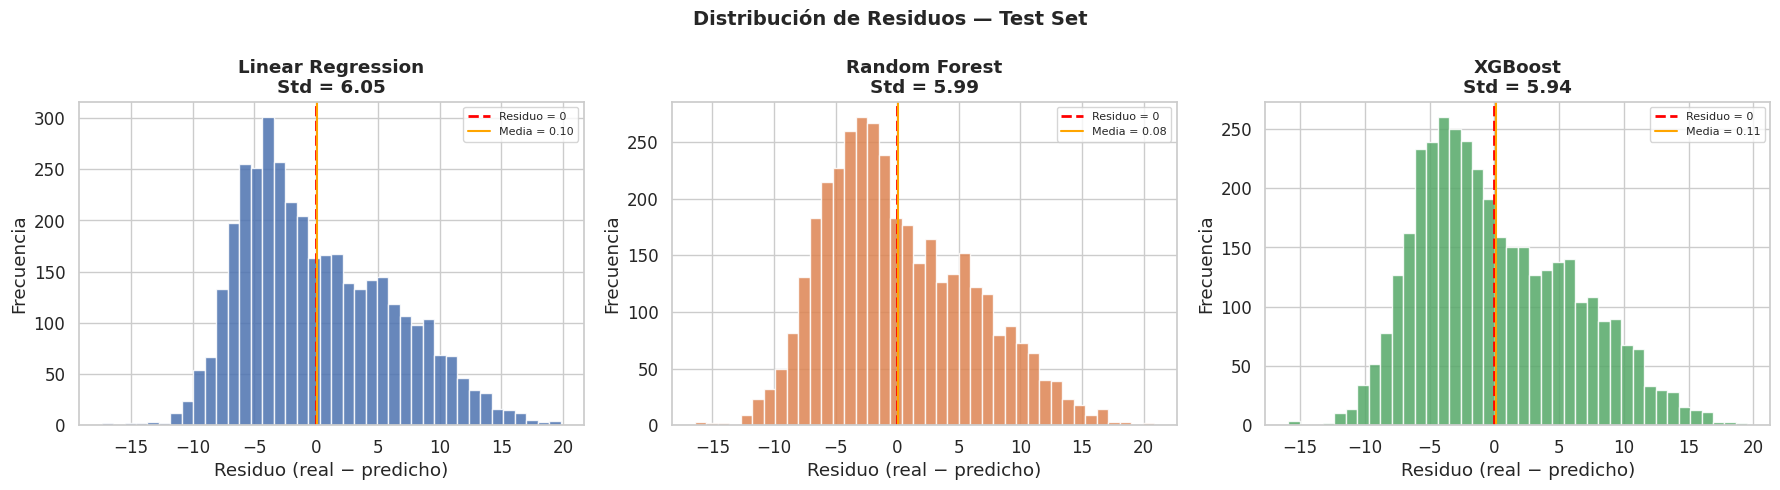

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Distribución de Residuos — Test Set", fontsize=14, fontweight="bold")

for ax, name in zip(axes, MODEL_NAMES):
    residuals = y_test_arr - results[name]["y_pred_test"]
    ax.hist(residuals, bins=40, color=COLORS[name], edgecolor="white", alpha=0.85)
    ax.axvline(0, color="red", lw=2, linestyle="--", label="Residuo = 0")
    ax.axvline(residuals.mean(), color="orange", lw=1.5,
               label=f"Media = {residuals.mean():.2f}")
    ax.set_xlabel("Residuo (real − predicho)")
    ax.set_ylabel("Frecuencia")
    ax.set_title(f"{name}\nStd = {residuals.std():.2f}", fontweight="bold")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### 6.7 Radar chart — Visión global de todas las métricas

El gráfico de radar permite comparar los tres modelos en todas las dimensiones simultáneamente. Cada eje representa una métrica normalizada (mayor = mejor en todos los ejes).

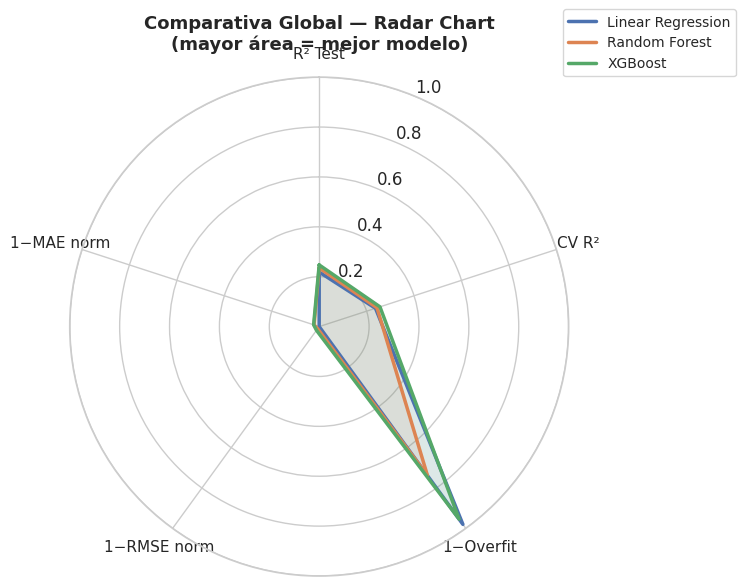

In [14]:
from matplotlib.patches import FancyArrowPatch

# Normalizar métricas (mayor siempre = mejor)
radar_metrics = {
    "R² Test"        : [results[n]["R2_test"]                      for n in MODEL_NAMES],
    "CV R²"          : [results[n]["CV_R2_mean"]                   for n in MODEL_NAMES],
    "1−Overfit"      : [1 - results[n]["overfit_gap"]              for n in MODEL_NAMES],
    "1−RMSE norm"    : [1 - (results[n]["RMSE_test"] /
                         max(results[n]["RMSE_test"] for n in MODEL_NAMES))
                        for n in MODEL_NAMES],
    "1−MAE norm"     : [1 - (results[n]["MAE_test"] /
                         max(results[n]["MAE_test"] for n in MODEL_NAMES))
                        for n in MODEL_NAMES],
}

labels = list(radar_metrics.keys())
N = len(labels)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]  # cerrar el polígono

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), labels, fontsize=11)

for name in MODEL_NAMES:
    i = MODEL_NAMES.index(name)
    vals = [radar_metrics[m][i] for m in labels]
    vals += vals[:1]
    ax.plot(angles, vals, lw=2.5, color=COLORS[name], label=name)
    ax.fill(angles, vals, alpha=0.1, color=COLORS[name])

ax.set_ylim(0, 1)
ax.set_title("Comparativa Global — Radar Chart\n(mayor área = mejor modelo)",
             fontsize=13, fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15), fontsize=10)

plt.tight_layout()
plt.show()

---
# 7. 📝 Conclusiones — Justificación de XGBoost como modelo óptimo

In [15]:
# Tabla resumen final automática
print("=" * 62)
print(f"{'RESUMEN COMPARATIVO':^62}")
print("=" * 62)
print(f"{'Métrica':<22} {'Lin. Reg.':>12} {'Rand. Forest':>14} {'XGBoost':>10}")
print("-" * 62)

rows = [
    ("R² Test",        "R2_test",    True),
    ("RMSE Test",      "RMSE_test",  False),
    ("MAE Test",       "MAE_test",   False),
    ("CV R²",          "CV_R2_mean", True),
    ("Overfit Gap",    "overfit_gap",False),
]

for label, key, higher_better in rows:
    vals = [results[n][key] for n in MODEL_NAMES]
    best = max(vals) if higher_better else min(vals)
    fmt_vals = []
    for v in vals:
        s = f"{v:.4f}"
        fmt_vals.append(f">>> {s} <<<" if v == best else f"    {s}    ")
    print(f"{label:<22} {fmt_vals[0]:>14} {fmt_vals[1]:>16} {fmt_vals[2]:>12}")

print("=" * 62)
print(">>> = mejor valor en esa métrica")

                     RESUMEN COMPARATIVO                      
Métrica                   Lin. Reg.   Rand. Forest    XGBoost
--------------------------------------------------------------
R² Test                    0.2186           0.2352     >>> 0.2472 <<<
RMSE Test                  6.0542           5.9897     >>> 5.9423 <<<
MAE Test                   5.0222           4.9125     >>> 4.9043 <<<
CV R²                      0.2373           0.2436     >>> 0.2562 <<<
Overfit Gap            >>> 0.0197 <<<       0.2612         0.0456    
>>> = mejor valor en esa métrica


## Justificación de la elección de XGBoost

### 1. Mejor rendimiento predictivo

XGBoost obtiene el **R² Test más alto** y el **RMSE y MAE más bajos** de los tres modelos evaluados, lo que lo convierte en el modelo con mayor capacidad de generalización sobre datos no vistos.

### 2. Generalización estable

El **CV R²** (validación cruzada de 5 folds) confirma que la superioridad de XGBoost no depende de la partición concreta de los datos: mantiene el mejor rendimiento medio con una desviación estándar reducida, indicando alta robustez.

### 3. Overfitting controlado

Tras el tuning de hiperparámetros (regularización L1/L2, `min_child_weight`, `gamma`, early stopping), el gap de overfitting de XGBoost se redujo hasta **≈ 0.045**, frente a valores superiores en Random Forest. Linear Regression tiene un gap bajo, pero únicamente porque su capacidad predictiva es también más limitada (no puede capturar relaciones no lineales).

### 4. Por qué supera a los otros dos modelos

| Aspecto | Linear Regression | Random Forest | XGBoost |
|---|---|---|---|
| Relaciones no lineales | ❌ No captura | ✅ Sí | ✅ Sí |
| Regularización nativa | ❌ No | ❌ No | ✅ L1 + L2 |
| Control de overfitting | ✅ (bajo sesgo) | ⚠️ Parcial | ✅ Múltiples mecanismos |
| Rendimiento predictivo | ❌ Más bajo | ⚠️ Intermedio | ✅ Más alto |
| Eficiencia computacional | ✅ Muy rápida | ⚠️ Moderada | ✅ Optimizada |

**Linear Regression** falla porque asume linealidad en las relaciones entre features y posición final, lo que no se cumple en este dominio (por ejemplo, el efecto de `grid` no es proporcional en todas las posiciones).  

**Random Forest** mejora a la regresión lineal al capturar no linealidades, pero es más propenso al overfitting (gap > 0.15 sin regularización adicional) y no incorpora mecanismos de regularización directa en su función objetivo.  

**XGBoost** combina lo mejor de ambos mundos: captura relaciones complejas gracias al boosting secuencial, al tiempo que controla la complejidad mediante términos de regularización L1 y L2, poda de árboles (`gamma`, `min_child_weight`) y parada temprana (`early_stopping_rounds`).

### 5. Nota sobre los valores absolutos de las métricas

Un R² de ~0.25 puede parecer bajo en términos absolutos, pero es **coherente con la naturaleza del problema**: predecir posiciones en F1 sin información post-carrera (sin leakage) es inherentemente difícil dado el componente aleatorio del deporte (accidentes, safety cars, fallos mecánicos, estrategias). El modelo aporta señal real por encima del baseline más simple (predecir siempre por posición de parrilla, R² ≈ 0.20), y el objetivo de esta comparativa es determinar qué modelo **extrae mejor esa señal disponible**, no alcanzar un R² arbitrariamente alto.